In [1]:
import numpy as np
import control as ctrl
import matplotlib.pyplot as plt

# Diseño para un motor de corriente continua

Supongamos que la transferencia de nuestro sistema es:

$$G(s)=\frac{10}{s(s+2)(s+8)}$$

Diseñar un controlador que ubique los polos en:

$$pc=[-1.42;\quad -1.04\pm2.14j]$$

y los del estimador tres veces más rápidos.

Como tenemos el sistema en forma de función transferencia, lo llevamos a una forma en espacio de estados.

In [2]:
G=ctrl.tf(10,[1,10,16,0])
G

TransferFunction(
array([10]),
array([ 1, 10, 16,  0]),
outputs=1, inputs=1)

## Expresión en variables de estado

De las formas canónicas disponibles (ver `help(ctrl.canonical_form)`), elegimos la forma canónica de observabilidad.

In [3]:
sys,_=ctrl.canonical_form(ctrl.ss(G),'observable')
sys

StateSpace(
array([[-10.,   1.,   0.],
       [-16.,   0.,   1.],
       [ -0.,   0.,   0.]]),
array([[-1.48029737e-16],
       [-1.40165657e-15],
       [ 1.00000000e+01]]),
array([[1., 0., 0.]]),
array([[0.]]),
states=3, outputs=1, inputs=1)

## Ley de control y estimador completo

In [4]:
pc=np.array([-1.42, -1.04+2.14j,-1.04-2.14j])
pe = pc*3

Notar que podríamos haber escrito `pc` como una lista de los valores donde queremos ubicar los polos a lazo cerrado. Sin embargo, luego `pc*3` sobre una lista repetiría la lista tres veces en lugar de multiplicar cada polo por 3.

**Obtenemos la ley de control:**

In [5]:
K=ctrl.place(sys.A,sys.B,pc)

**Obtenemos L del estimador:**

In [6]:
L=ctrl.place(sys.A.T,sys.C.T,pe).T

Hemos podido utilizar el comando `place` debido a que los 3 polos, tanto del estimador como de la ley de control, son distintos. De haber querido ubicar dos polos en el mismo lugar, hubiéramos tenido que usar el comando `acker`.

Sin embargo, es necesario tener en cuenta que `acker` es numéricamente poco confiable para sistemas de orden mayor a 4.

### Sistema controlador con estimador completo

In [7]:
Dc=ctrl.ss(sys.A-sys.B@K-L@sys.C,L,-K,0)
ctrl.tf(Dc)

TransferFunction(
array([-190.23408114, -483.02332145, -174.48473931]),
array([   1.      ,    4.      ,   66.898   , -146.069088]),
outputs=1, inputs=1)

In [8]:
Dc.poles()

array([-2.93739746+8.32368499j, -2.93739746-8.32368499j,
        1.87479491+0.j        ])

Podemos ver que el controlador diseñado es inestable. Esto no es deseable.

Las razones por las que no es deseable un controlador inestable son:

1. Presenta dificultades para ser probado, ya sea el compensador por sí solo o en lazo abierto durante la puesta en funcionamiento. Sin embargo, en algunos casos se puede lograr una mejor performance del sistema controlado con un controlador inestable (hay sistemas que ni siquiera pueden ser estabilizados con controladores estables). En ese caso se aceptan estos inconvenientes.

2. Para ganancias bajas, el sistema a lazo cerrado con un controlador inestable resulta inestable (ver el lugar de las raíces). En general, los actuadores presentan saturaciones, es decir, valores máximos de actuación. Cuando un actuador satura, desde el punto de vista del lazo se ve como una reducción de la ganancia, que lleva al sistema a la zona inestable o lo acerca a ella.

Los sistemas que se vuelven inestables cuando su ganancia se reduce se conocen como sistemas **condicionalmente estables** y **deben ser evitados** en la medida de lo posible.

## Rediseñamos usando un estimador reducido

Ahora pondremos los polos tal que $\omega_n=6$ rad/seg y $\zeta=0.707$

In [9]:
pe_red= np.roots([1,2*0.707*6,6**2])
pe_red

array([-4.242+4.24328128j, -4.242-4.24328128j])

Necesitamos las submatrices de $\mathbf A$ y $\mathbf B$ para calcular el estimador reducido:

In [10]:
Aaa=sys.A[0:1,0:1]
Aab=sys.A[0:1,1:]
Aba=sys.A[1:,0:1]
Abb=sys.A[1:,1:]

Ba = sys.B[0:1,0:]
Bb = sys.B[1:,0:]

Ahora calculemos el estimador reducido.

In [11]:
Ltred = ctrl.place(Abb.T,Aab.T,pe_red).T
Ltred

array([[ 8.484],
       [36.   ]])

### Sistema controlador con estimador reducido

In [12]:
Ka=K[0:1,0:1]
Kb=K[0:1,1:]

Ar = Abb-Ltred@Aab-(Bb-Ltred@Ba)@Kb
Br = Ar@Ltred + Aba - Ltred@Aaa - (Bb-Ltred@Ba)@Ka
Cr = -Kb
Dr = -Ka-Kb@Ltred

In [13]:
Dcr = ctrl.ss(Ar,Br,Cr,Dr)
Dcr

StateSpace(
array([[ -8.484 ,   1.    ],
       [-93.6148,   6.5   ]]),
array([[ 32.861744 ],
       [263.8811328]]),
array([[-5.76148,  0.65   ]]),
array([[20.93051328]]),
states=2, outputs=1, inputs=1)

In [14]:
ctrl.tf(Dcr)

TransferFunction(
array([ 20.93051328,  23.71659385, -28.9400544 ]),
array([ 1.    ,  1.984 , 38.4688]),
outputs=1, inputs=1)

In [15]:
Dcr.poles()

array([-0.992+6.12247793j, -0.992-6.12247793j])

In [16]:
Dcr.zeros()

array([-1.871798  +0.j,  0.73868705+0.j])

Si bien este diseño mejora al anterior, ya que el controlador resultante es estable, presenta un problema potencialmente menos dañino: es un controlador de fase no mínima, ya que tiene un cero en el semiplano derecho del plano $s$, lo que limita la velocidad del sistema controlado.

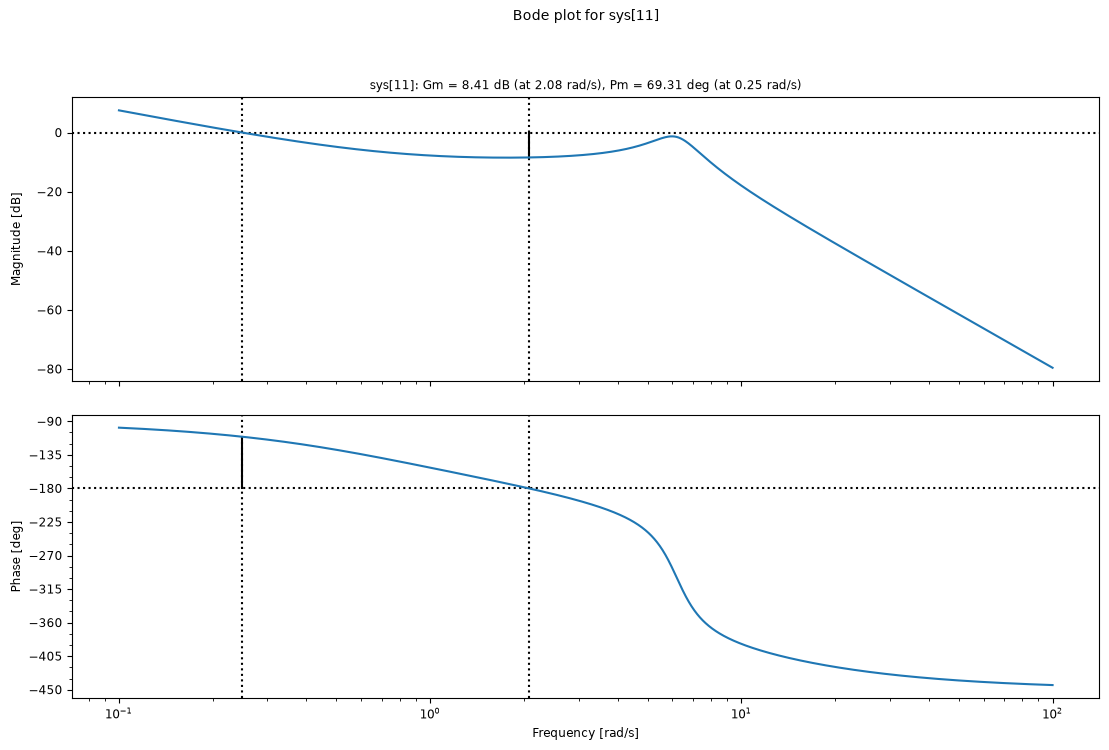

In [17]:
Lr=-ctrl.tf(Dcr)*G/ctrl.db2mag(6)
ctrl.bode(Lr,dB=True, display_margins=True, omega_num=2000);
plt.gcf().set_size_inches(12,8)

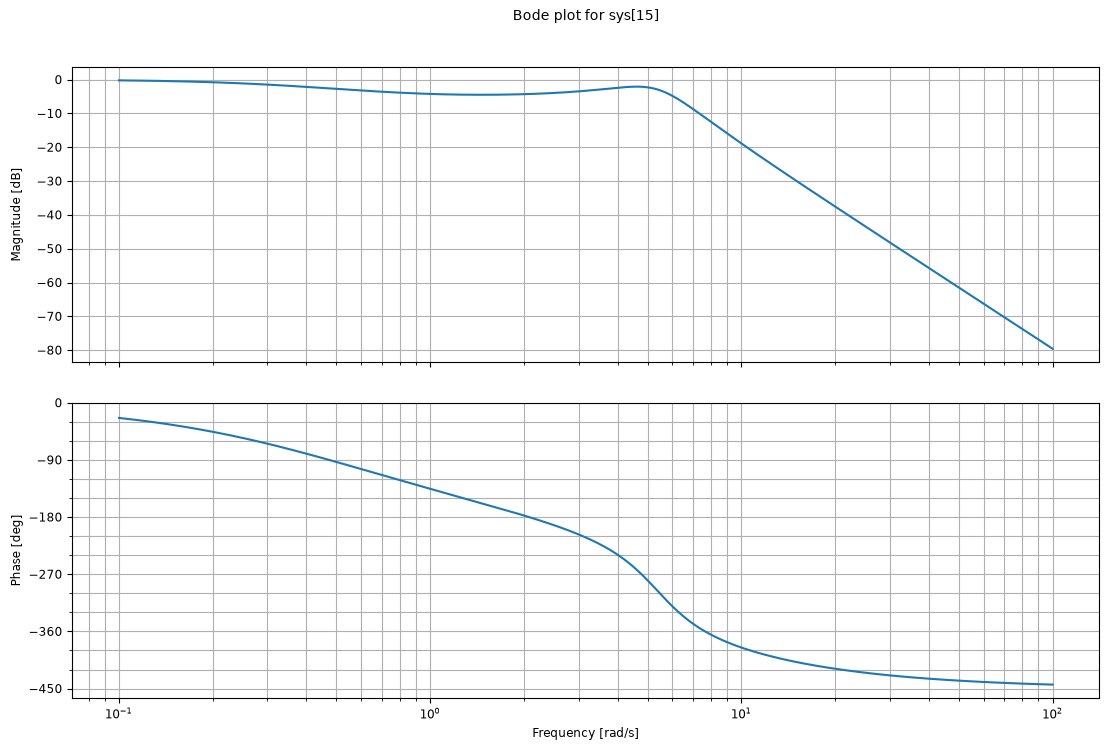

In [18]:
T=ctrl.feedback(Lr)
plt.figure()
ctrl.bode(T,dB=True);
plt.gcf().set_size_inches(12,8)

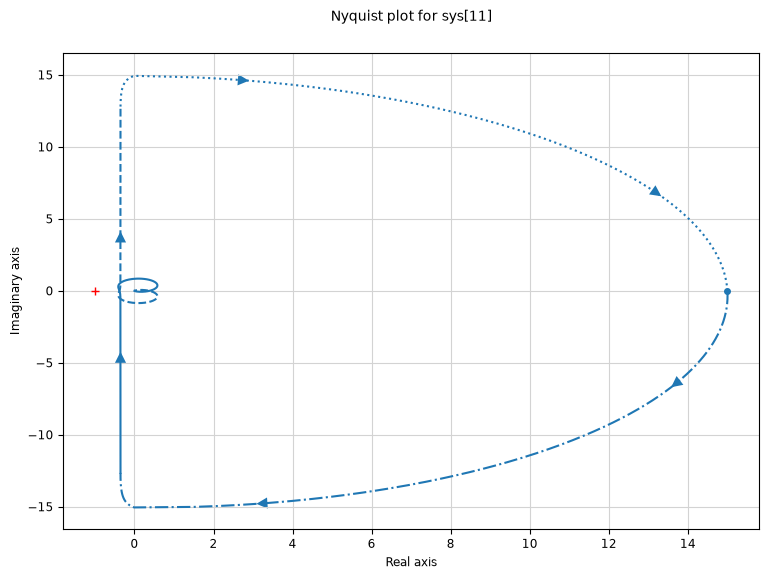

In [19]:
_=ctrl.nyquist(Lr);
plt.gcf().set_size_inches(8,6)

Agregamos la referencia al controlador de orden reducido (ver la sección de inserción de referencias).

In [20]:
def seguimiento_referencia(sys):
    aux1=np.vstack((np.hstack((sys.A,sys.B)),
                   np.hstack((sys.C,sys.D))))
    n=np.shape(sys.A)[0]
    aux2=np.vstack((np.zeros((n,1)),[1]))
    N=np.linalg.inv(aux1)@aux2
    Nx=N[0:n]
    Nu=N[n]
    return Nx, Nu

def calculate_Nbar(Nx,Nu,K):
    return Nu+K@Nx

In [21]:
Nx, Nu = seguimiento_referencia(sys)
Nbar = calculate_Nbar(Nx,Nu, K)
Nbar

array([[0.8038904]])

In [22]:
N=Nbar
M=(Bb-Ltred@Ba)@N
M

array([[-1.17184939e-16],
       [ 8.03890400e+00]])

In [23]:
Dcr_ref = ctrl.ss(Ar, np.hstack((Br,M)), Cr, np.hstack((Dr,N)))
Dcr_ref

StateSpace(
array([[ -8.484 ,   1.    ],
       [-93.6148,   6.5   ]]),
array([[ 3.28617440e+01, -1.17184939e-16],
       [ 2.63881133e+02,  8.03890400e+00]]),
array([[-5.76148,  0.65   ]]),
array([[20.93051328,  0.8038904 ]]),
states=2, outputs=1, inputs=2)

## Rediseño usando SRL

Vamos a diseñar el sistema para ubicar los polos de forma tal que se tenga un ancho de banda de 2.5 rad/s y que los polos del estimador estén aproximadamente 2.5 veces más rápidos.

Para usar el lugar simétrico de las raíces (LSR) vamos a tomar $\mathbf{C_1} = \mathbf{C}$ para la ley de control y $\mathbf{B_1} = \mathbf{B}$ para el estimador, de modo que en ambos casos se usa $G(-s)G(s)$.

In [24]:
def conjugate_tf(G):
    """Devuelve G(-s) para un sistema SISO."""
    num = ctrl.tf(G).num[0][0]
    den = ctrl.tf(G).den[0][0]
    # el coeficiente i multiplica a s^(n-1-i)
    nume = [c*(-1)**(len(num)-1-i) for i, c in enumerate(num)]
    dene = [c*(-1)**(len(den)-1-i) for i, c in enumerate(den)]
    return ctrl.tf(nume, dene)

In [25]:
Gm=conjugate_tf(G)
Gm

TransferFunction(
array([10]),
array([ -1,  10, -16,   0]),
outputs=1, inputs=1)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


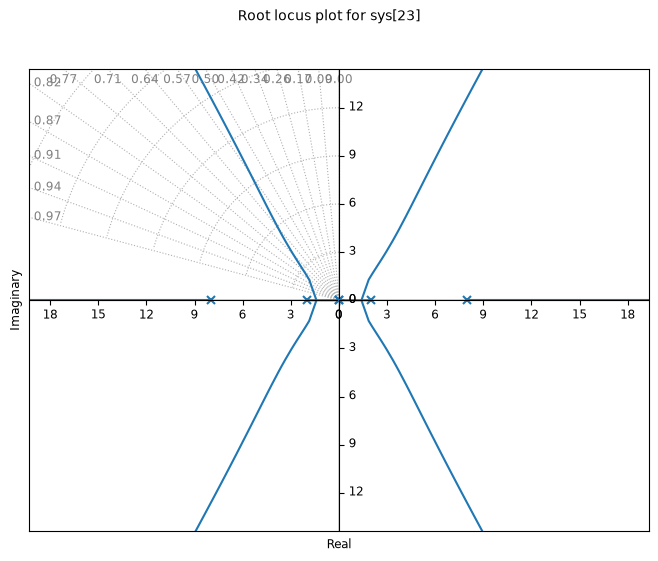

In [26]:
_=ctrl.rlocus(G*Gm)
plt.gcf().set_size_inches(8,6)

Con $\rho=26$ obtenemos los polos con una frecuencia de corte de 2.5 rad/s.

In [27]:
pc = ctrl.root_locus_map(G*Gm, gains=[26]).loci[0]
pc = pc[pc.real<0]
pc

array([-8.04131959+0.j        , -2.00120126-1.52846879j,
       -2.00120126+1.52846879j])

Y con $\rho=1350$ tenemos los polos del estimador.

In [28]:
pe = ctrl.root_locus_map(G*Gm, gains=[1350]).loci[0]
pe = pe[pe.real<0]
pe

array([-9.16842047+0.j        , -4.00280684-4.90432763j,
       -4.00280684+4.90432763j])

In [29]:
print("Polos de la ley de control: ",pc)
print("Polos del estimador: ",pe)

Polos de la ley de control:  [-8.04131959+0.j         -2.00120126-1.52846879j -2.00120126+1.52846879j]
Polos del estimador:  [-9.16842047+0.j         -4.00280684-4.90432763j -4.00280684+4.90432763j]


In [30]:
K=ctrl.place(sys.A,sys.B,pc)
L=ctrl.place(sys.A.T,sys.C.T,pe).T

In [31]:
Dcsrl=ctrl.ss(sys.A-sys.B@K-L@sys.C,L,-K,0)
ctrl.tf(Dcsrl)

TransferFunction(
array([  -93.58707346,  -981.95825666, -1873.49939952]),
array([  1.        ,  19.21775626, 150.66107776, 632.60511522]),
outputs=1, inputs=1)

In [32]:
Dcsrl.poles()

array([-10.64805029+0.j        ,  -4.28485298+6.40706271j,
        -4.28485298-6.40706271j])

In [33]:
Dcsrl.zeros()

array([-2.50686229+0.j, -7.98559378+0.j])

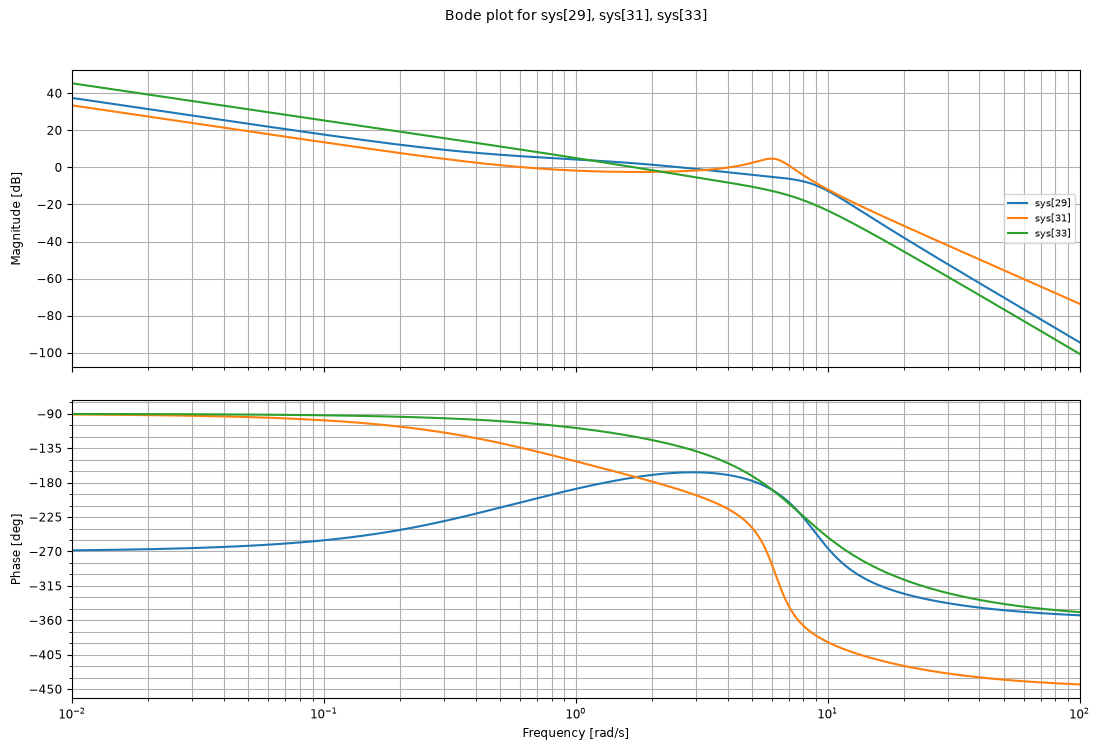

In [34]:
_=ctrl.bode((-sys*Dc,-sys*Dcr,-sys*Dcsrl),omega_limits=(1e-2,1e2),dB=True)
plt.gcf().set_size_inches(12,8)

In [35]:
print(ctrl.margin(-sys*Dc))
print(ctrl.margin(-sys*Dcr))
print(ctrl.margin(-sys*Dcsrl))

(np.float64(0.681728320867242), np.float64(13.183302483785099), np.float64(1.3027826533896698), np.float64(2.6082921725544588))
(np.float64(1.3198762960800339), np.float64(-35.20865106169251), np.float64(2.078898635880746), np.float64(4.0582116626183655))
(np.float64(3.781844592593218), np.float64(60.0956170847183), np.float64(5.497487495572337), np.float64(1.7117848527162791))


In [36]:
T1=ctrl.feedback(-sys*Dc)
T2=ctrl.feedback(-sys*Dcr)
T3=ctrl.feedback(-sys*Dcsrl)

In [37]:
print(f"Los polos de T1 son: {T1.poles()}")
print(f"Los polos de T2 son: {T2.poles()}")
print(f"Los polos de T3 son: {T3.poles()}")

Los polos de T1 son: [-3.12+6.42j -3.12-6.42j -1.04+2.14j -1.04-2.14j -1.42+0.j   -4.26+0.j  ]
Los polos de T2 son: [-4.242+4.24328128j -4.242-4.24328128j -1.04 +2.14j
 -1.04 -2.14j       -1.42 +0.j        ]
Los polos de T3 son: [-9.16842047+0.j         -8.04131959+0.j         -4.00280684+4.90432763j
 -4.00280684-4.90432763j -2.00120126+1.52846879j -2.00120126-1.52846879j]


### Respuesta del sistema controlado a condiciones iniciales (salida inicial distinta de 0)

In [38]:
t1,y1 = ctrl.initial_response(T1, X0=[0,0,0,-1,0,0], T=np.linspace(0,5,1000))
t2,y2 = ctrl.initial_response(T2, X0=[0,0,-1,0,0], T=np.linspace(0,5,1000))
t3,y3 = ctrl.initial_response(T3, X0=[0,0,0,-1,0,0], T=np.linspace(0,5,1000))

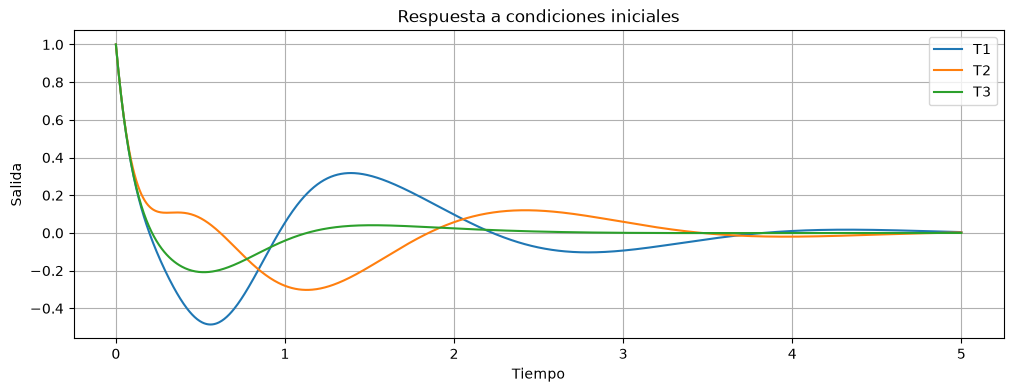

In [39]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(t1,y1,label="T1")
ax.plot(t2,y2,label="T2")
ax.plot(t3,y3,label="T3")
plt.legend()
ax.set_title('Respuesta a condiciones iniciales')
ax.set_xlabel("Tiempo")
ax.set_ylabel("Salida")
ax.grid()

## Conexión de sistemas entrada/salida

Podemos ver en el caso anterior que, al usar la función `ctrl.feedback`, perdemos (al menos parcialmente) el conocimiento de cómo están ordenados los estados del sistema.

Para tener mayor control de cómo están ubicados los estados, las entradas y las salidas, es conveniente usar la función `ctrl.interconnect`, que conecta sistemas a partir de los nombres de sus señales.

Primero damos nombre a las señales de la planta y de los controladores. La planta tiene entrada `u` y salida `y`; los controladores tienen entrada `y` y salida `uc`. Además definimos un sumador que forma la entrada de la planta como `u = uc + w`, donde `w` es una entrada auxiliar:

In [40]:
planta = ctrl.ss(sys.A, sys.B, sys.C, sys.D, inputs='u', outputs='y', name='planta')
suma = ctrl.summing_junction(inputs=['uc', 'w'], output='u', name='suma')

def controlador(Dsys):
    return ctrl.ss(Dsys.A, Dsys.B, Dsys.C, Dsys.D, inputs='y', outputs='uc', name='controlador')

Ahora conectamos la planta con cada uno de los tres controladores:

In [41]:
sys_conectado_1 = ctrl.interconnect([planta, controlador(Dc), suma], inplist='w', outlist=['y','uc'])
sys_conectado_1

<LinearICSystem sys[59]: ['u[0]'] -> ['y[0]', 'y[1]']>

In [42]:
sys_conectado_2 = ctrl.interconnect([planta, controlador(Dcr), suma], inplist='w', outlist=['y','uc'])
sys_conectado_2

<LinearICSystem sys[61]: ['u[0]'] -> ['y[0]', 'y[1]']>

In [43]:
sys_conectado_3 = ctrl.interconnect([planta, controlador(Dcsrl), suma], inplist='w', outlist=['y','uc'])
sys_conectado_3

<LinearICSystem sys[63]: ['u[0]'] -> ['y[0]', 'y[1]']>

La manera en que `ctrl.interconnect` trabaja es:

1. El primer argumento es la lista de sistemas que se quieren interconectar. Cada sistema tiene sus entradas y salidas con nombre.

2. Las señales que tienen el mismo nombre se conectan automáticamente: la salida `y` de la planta se conecta con la entrada `y` del controlador, y la salida `uc` del controlador con la entrada `uc` del sumador, cuya salida `u` es la entrada de la planta.

3. `inplist` indica qué entradas son las del sistema completo. Aquí no hay una referencia, pero el módulo de control tiene algunos problemas con sistemas sin entradas. Por eso tomamos como entrada la señal auxiliar `w`, que se suma a la salida del controlador en la entrada de la planta.

4. `outlist` indica las salidas del sistema completo. Tomamos la salida de la planta `y` y el esfuerzo de control `uc`.

Los estados del sistema conectado quedan ordenados según el orden de la lista: primero los 3 estados de la planta y luego los del controlador (el observador).

Vamos a realizar nuevamente las simulaciones con los sistemas definidos mediante `interconnect`.

In [44]:
t1,y1 = ctrl.initial_response(sys_conectado_1, X0=[1,0,0,0,0,0], T=np.linspace(0,5,1000))
t2,y2 = ctrl.initial_response(sys_conectado_2, X0=[1,0,0,0,0], T=np.linspace(0,5,1000))
t3,y3 = ctrl.initial_response(sys_conectado_3, X0=[1,0,0,0,0,0], T=np.linspace(0,5,1000))

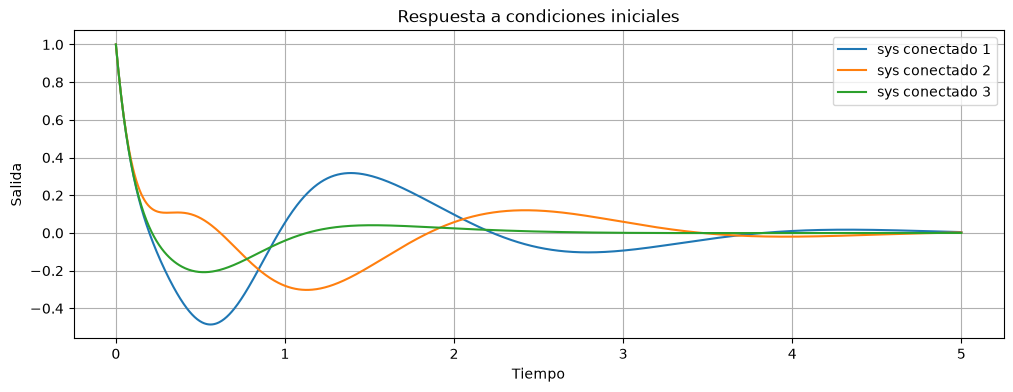

In [45]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(t1,y1[0,:],label="sys conectado 1")
ax.plot(t2,y2[0,:],label="sys conectado 2")
ax.plot(t3,y3[0,:],label="sys conectado 3")
plt.legend()
ax.set_title('Respuesta a condiciones iniciales')
ax.set_xlabel("Tiempo")
ax.set_ylabel("Salida")
ax.grid()

Podemos también mirar el esfuerzo de control, ya que es una salida del sistema conectado.

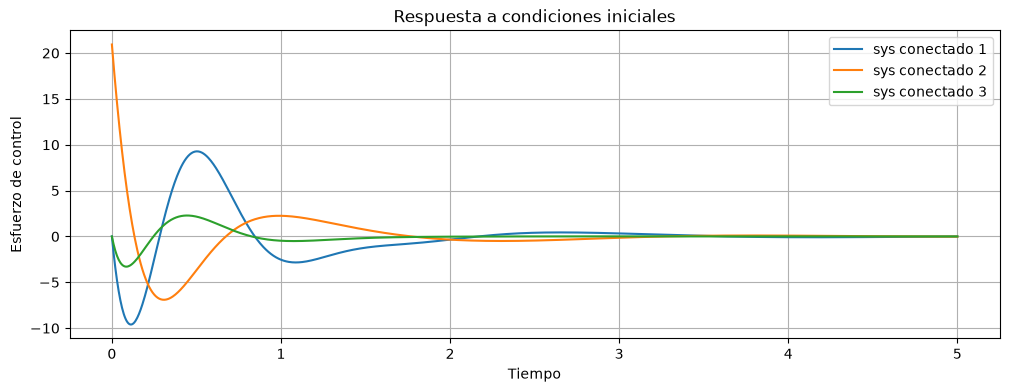

In [46]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(t1,y1[1,:],label="sys conectado 1")
ax.plot(t2,y2[1,:],label="sys conectado 2")
ax.plot(t3,y3[1,:],label="sys conectado 3")
plt.legend()
ax.set_title('Respuesta a condiciones iniciales')
ax.set_xlabel("Tiempo")
ax.set_ylabel("Esfuerzo de control")
ax.grid()

Este ejemplo muestra claramente cómo la elección de los polos usando criterios de optimización, como el del lugar simétrico de las raíces, nos da un control mucho mejor, tanto en tiempo de respuesta como en esfuerzo de control.

### Seguimiento de referencia con el estimador reducido

Conectamos la planta con el controlador de orden reducido con referencia, `Dcr_ref`, que tiene dos entradas: la salida de la planta `y` y la referencia `r`. El sistema conectado tiene como entrada la referencia y como salidas la salida de la planta `y` y el esfuerzo de control `u`.

In [47]:
Dcr_ref_n = ctrl.ss(Dcr_ref.A, Dcr_ref.B, Dcr_ref.C, Dcr_ref.D,
                    inputs=['y','r'], outputs='u', name='controlador')
psys_controlado_con_ref = ctrl.interconnect([planta, Dcr_ref_n], inplist='r', outlist=['y','u'])
psys_controlado_con_ref.poles()

array([-4.242+4.24328128j, -4.242-4.24328128j, -1.04 +2.14j      ,
       -1.04 -2.14j      , -1.42 +0.j        ])

La ganancia en continua desde la referencia hasta la salida debe ser 1:

In [48]:
ctrl.dcgain(psys_controlado_con_ref)

array([[1.00000000e+00],
       [5.32907052e-15]])

In [49]:
t,y = ctrl.step_response(psys_controlado_con_ref)

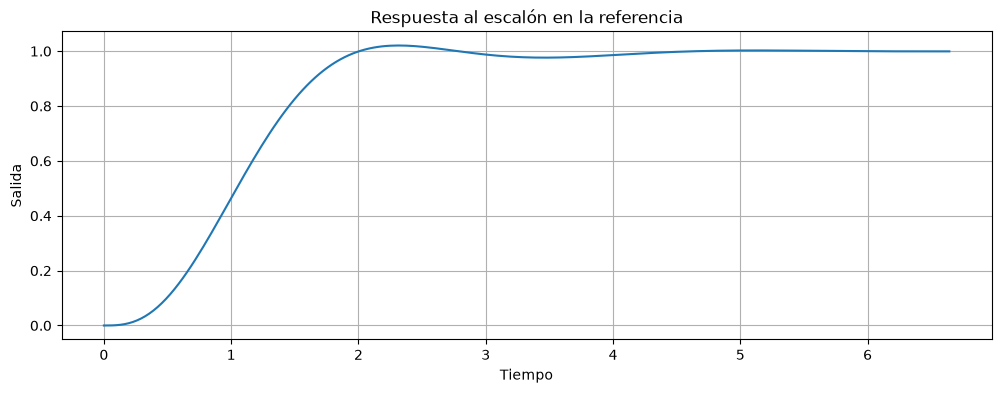

In [50]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(t,y[0,:].T,label="psys conectado con ref")
ax.set_title('Respuesta al escalón en la referencia')
ax.set_xlabel("Tiempo")
ax.set_ylabel("Salida")
ax.grid()

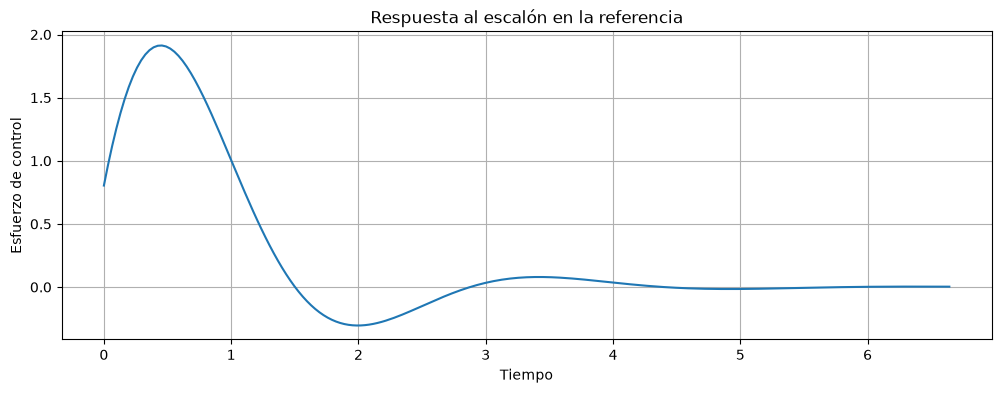

In [51]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(t,y[1,:].T,label="psys conectado con ref")
ax.set_title('Respuesta al escalón en la referencia')
ax.set_xlabel("Tiempo")
ax.set_ylabel("Esfuerzo de control")
ax.grid()

## Control integral y estimador de orden completo

Para obtener error nulo en estado estacionario de forma robusta, agregamos un estado integrador $x_I$ con $\dot x_I = y - r$. El sistema aumentado (con $r=0$) es:

$$
\begin{bmatrix}\dot x_I\\ \dot{\mathbf x}\end{bmatrix} =
\underbrace{\begin{bmatrix} 0 & \mathbf C\\ \mathbf 0 & \mathbf A\end{bmatrix}}_{\mathbf A_u}
\begin{bmatrix} x_I\\ \mathbf x\end{bmatrix} +
\underbrace{\begin{bmatrix} 0\\ \mathbf B\end{bmatrix}}_{\mathbf B_u} u
$$

y diseñamos una ley de control $u = -\mathbf K_u [x_I \;\; \mathbf x]^T = -K_i x_I - \mathbf K \mathbf x$ para el sistema aumentado.

In [52]:
Au=np.vstack((np.hstack((np.zeros((1,1)), sys.C)),
              np.hstack((np.zeros((3,1)), sys.A))))
Au

array([[  0.,   1.,   0.,   0.],
       [  0., -10.,   1.,   0.],
       [  0., -16.,   0.,   1.],
       [  0.,  -0.,   0.,   0.]])

In [53]:
Bu = np.vstack((0,sys.B))
Bu

array([[ 0.00000000e+00],
       [-1.48029737e-16],
       [-1.40165657e-15],
       [ 1.00000000e+01]])

In [54]:
Ku = ctrl.place(Au,Bu, np.array([-1.42, -1.04+2.14j,-1.04-2.14j, -3]))
Ku

array([[  2.4116712, -29.1264696,   3.81148  ,  -0.35     ]])

In [55]:
Ki=Ku[0,0]
Ki

np.float64(2.4116712000000406)

El integrador calcula $K_i\int (r - y)\,dt = -K_i x_I$; su entrada 1 es la referencia y su entrada 2 la salida de la planta:

In [56]:
integrador=ctrl.ss([[0]],[[Ki,-Ki]],[1],[0, 0])
integrador

StateSpace(
array([[0.]]),
array([[ 2.4116712, -2.4116712]]),
array([[1.]]),
array([[0., 0.]]),
states=1, outputs=1, inputs=2)

In [57]:
# Estimador más ley de control

L=ctrl.place(sys.A.T, sys.C.T, np.array([-1.42, -1.04+2.14j,-1.04-2.14j])*3).T
L

array([[  0.5     ],
       [ 61.5332  ],
       [217.050408]])

In [58]:
Ae=sys.A-L@sys.C
Ae

array([[ -10.5     ,    1.      ,    0.      ],
       [ -77.5332  ,    0.      ,    1.      ],
       [-217.050408,    0.      ,    0.      ]])

In [59]:
Be=np.hstack((L,sys.B))
Be

array([[ 5.00000000e-01, -1.48029737e-16],
       [ 6.15332000e+01, -1.40165657e-15],
       [ 2.17050408e+02,  1.00000000e+01]])

In [60]:
Ce=-Ku[0:1,1:]
Ce

array([[29.1264696, -3.81148  ,  0.35     ]])

In [61]:
De=0
estim = ctrl.ss(Ae,Be,Ce,De)
estim

StateSpace(
array([[ -10.5     ,    1.      ,    0.      ],
       [ -77.5332  ,    0.      ,    1.      ],
       [-217.050408,    0.      ,    0.      ]]),
array([[ 5.00000000e-01, -1.48029737e-16],
       [ 6.15332000e+01, -1.40165657e-15],
       [ 2.17050408e+02,  1.00000000e+01]]),
array([[29.1264696, -3.81148  ,  0.35     ]]),
array([[0., 0.]]),
states=3, outputs=1, inputs=2)

Conectamos la planta, el estimador y el integrador. El estimador recibe la salida de la planta `y` y la entrada de la planta `u`; la entrada de la planta es la suma de las salidas del estimador `ue` y del integrador `ui`; y la entrada del integrador `r` es la referencia. Tomamos como salidas la salida de la planta y el esfuerzo de control `u` total:

In [62]:
estim_n = ctrl.ss(estim.A, estim.B, estim.C, estim.D,
                  inputs=['y','u'], outputs='ue', name='estimador')
integrador_n = ctrl.ss(integrador.A, integrador.B, integrador.C, integrador.D,
                       inputs=['r','y'], outputs='ui', name='integrador')
suma_u = ctrl.summing_junction(inputs=['ue','ui'], output='u', name='suma_u')

planta_controlada = ctrl.interconnect([planta, estim_n, integrador_n, suma_u],
                                      inplist='r', outlist=['y','u'])
planta_controlada

<LinearICSystem sys[70]: ['u[0]'] -> ['y[0]', 'y[1]']>

In [63]:
t,y = ctrl.step_response(planta_controlada)

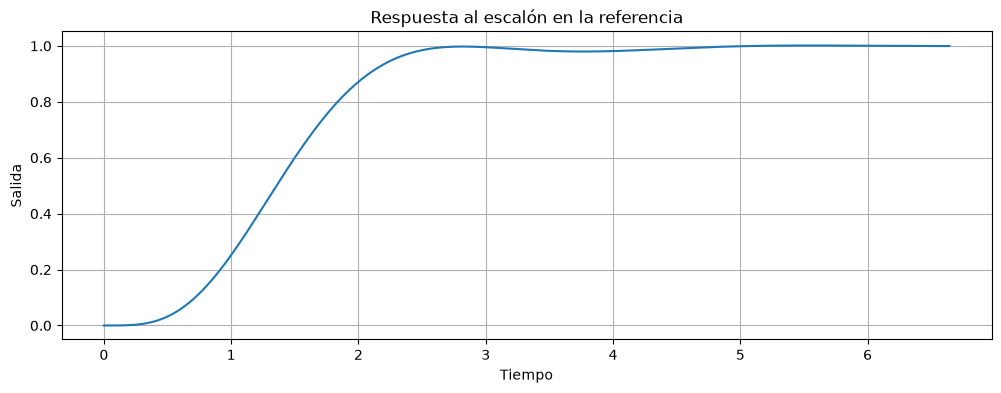

In [64]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(t,y[0,:].T,label="control integral")
ax.set_title('Respuesta al escalón en la referencia')
ax.set_xlabel("Tiempo")
ax.set_ylabel("Salida")
ax.grid()

In [65]:
planta_controlada.poles()

array([-3.12+6.42j, -3.12-6.42j, -1.04+2.14j, -1.04-2.14j, -4.26+0.j  ,
       -3.  +0.j  , -1.42+0.j  ])

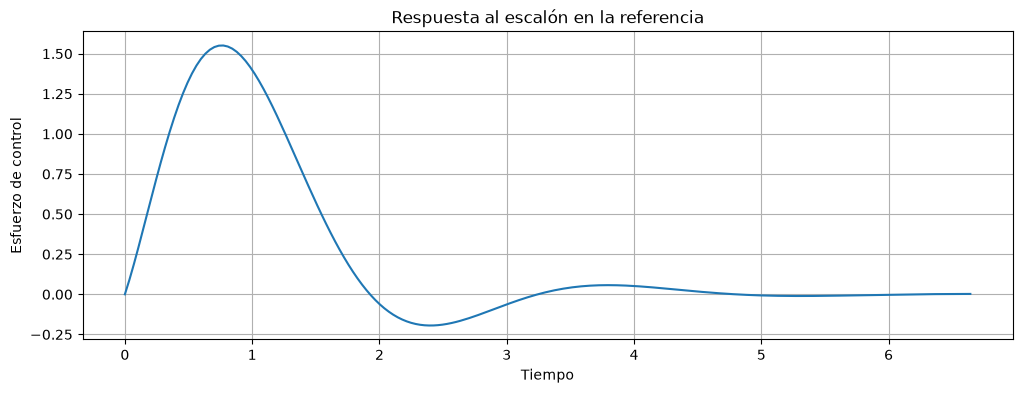

In [66]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(t,y[1,:].T,label="control integral")
ax.set_title('Respuesta al escalón en la referencia')
ax.set_xlabel("Tiempo")
ax.set_ylabel("Esfuerzo de control")
ax.grid()